# RANDOM FOREST

## What's in this notebook

- 3\. Random forest classifier
- 7\. Predict probabilities
- 8\. Number of trees
- 9\. Feature importance
- 10\. Feature importance plot
- 11\. Experiment with number of trees
- 12\. Experiment with max depth
- 13\. Random forest regression
- 15\. Random forest regressor
- 19\. Important parameters
- 20\. Interview notes

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import mean_squared_error, r2_score

# 1. CREATE CLASSIFICATION DATA

In [2]:
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=5,
    n_redundant=0,
    random_state=42
)

# 2. TRAIN / TEST SPLIT

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. RANDOM FOREST CLASSIFIER

In [4]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    max_features="sqrt",
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=42
)

# 4. TRAIN

In [5]:
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# 5. PREDICT

In [6]:
pred = model.predict(X_test)

# 6. EVALUATE

In [7]:
accuracy = accuracy_score(y_test, pred)

print("Accuracy:", accuracy)

print(classification_report(y_test, pred))

Accuracy: 0.94
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       100
           1       0.96      0.92      0.94       100

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.94       200
weighted avg       0.94      0.94      0.94       200



# 7. PREDICT PROBABILITIES

In [8]:
probabilities = model.predict_proba(X_test)

print(probabilities[:5])

[[0.33 0.67]
 [0.92 0.08]
 [0.91 0.09]
 [0.88 0.12]
 [0.37 0.63]]


# 8. NUMBER OF TREES

In [9]:
print("Number of trees:", len(model.estimators_))

Number of trees: 100


# 9. FEATURE IMPORTANCE

In [10]:
importance = model.feature_importances_

print("Feature importance:")
print(importance)

Feature importance:
[0.0750761  0.02793887 0.18385656 0.03675106 0.23329961 0.02808173
 0.03327094 0.1614704  0.1909939  0.02926083]


# 10. FEATURE IMPORTANCE PLOT

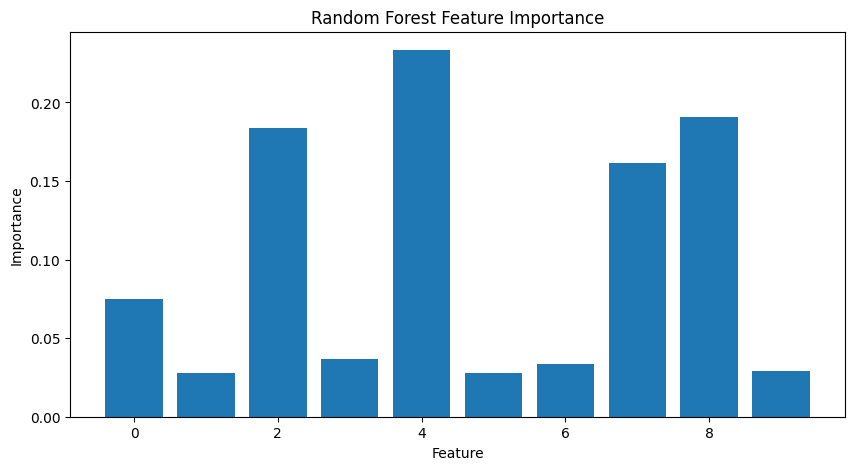

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    range(len(importance)),
    importance
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")

plt.show()

# 11. EXPERIMENT WITH NUMBER OF TREES

In [12]:
for n in [10, 50, 100, 200]:

    model = RandomForestClassifier(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)

    score = model.score(
        X_test,
        y_test
    )

    print(
        "n_estimators:",
        n,
        "Accuracy:",
        score
    )

n_estimators: 10 Accuracy: 0.92
n_estimators: 50 Accuracy: 0.945


n_estimators: 100 Accuracy: 0.94


n_estimators: 200 Accuracy: 0.945


# 12. EXPERIMENT WITH MAX DEPTH

In [13]:
for depth in [2, 5, 10, None]:

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_score = model.score(
        X_train,
        y_train
    )

    test_score = model.score(
        X_test,
        y_test
    )

    print(
        "max_depth:",
        depth,
        "| Train:",
        train_score,
        "| Test:",
        test_score
    )

max_depth: 2 | Train: 0.83625 | Test: 0.855


max_depth: 5 | Train: 0.94375 | Test: 0.925


max_depth: 10 | Train: 0.99625 | Test: 0.945


max_depth: None | Train: 1.0 | Test: 0.94


# 13. RANDOM FOREST REGRESSION

In [14]:
X_reg, y_reg = make_regression(
    n_samples=1000,
    n_features=10,
    n_informative=5,
    noise=10,
    random_state=42
)

# 14. TRAIN / TEST SPLIT

In [15]:
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

# 15. RANDOM FOREST REGRESSOR

```text
Random Forest
     ↓
Bootstrap samples
     ↓
Many Decision Trees
     ↓
Random features at each split
     ↓
Voting / Averaging
     ↓
Reduced variance
```

Note: `RandomForestRegressor` defaults to `max_features=1.0`, so every split sees **all** features. That is plain bagging. Set `max_features` (e.g. `0.3` or `"sqrt"`) to get the random-feature effect.

In [16]:
reg_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    max_features=1.0,
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=42
)

# 16. TRAIN

In [17]:
reg_model.fit(
    X_reg_train,
    y_reg_train
)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# 17. PREDICT

In [18]:
reg_pred = reg_model.predict(
    X_reg_test
)

# 18. EVALUATE

In [19]:
mse = mean_squared_error(
    y_reg_test,
    reg_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_reg_test,
    reg_pred
)

print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MSE: 276.59683235393123
RMSE: 16.631200568627968
R2: 0.9342554370131045


# 19. IMPORTANT PARAMETERS

```text
n_estimators
  Number of trees in the forest.

  More trees usually make the model more stable,
  but increase training/inference cost.


max_depth
  Maximum depth of every tree.

  Smaller → simpler trees
  Larger → more complex trees


max_features
  Number of features considered when searching
  for each split.

  "sqrt" is commonly used for classification.


min_samples_split
  Minimum number of samples required to split
  an internal node.


min_samples_leaf
  Minimum number of samples allowed in a leaf.


bootstrap
  Whether each tree is trained using a bootstrap
  sample of the training data.


max_samples
  Number/fraction of samples used for each tree
  when bootstrap=True.


class_weight
  Useful when classes are imbalanced.


random_state
  Makes the random process reproducible.
```

# 20. INTERVIEW NOTES

Random Forest = Bagging + Random Feature Selection

1. Create bootstrap samples.
2. Train a Decision Tree on each sample.
3. At every split, consider a random subset of features.
4. Classification → average the trees' predicted probabilities (soft voting); the class with the highest average wins.
5. Regression → average predictions.

Why does it work?

Individual trees have high variance.  
Random Forest creates diverse, less-correlated trees  
and combines them, reducing variance.

Random Forest vs Decision Tree:

```text
Decision Tree → one tree → high variance
Random Forest → many randomized trees → lower variance
```

Random Forest vs Gradient Boosting:

Random Forest:

```text
Trees are mostly independent.
Uses bagging.
Reduces variance.
Trees can be trained in parallel.
```

Gradient Boosting:

```text
Trees are sequential.
Each tree corrects previous errors.
Uses boosting.
Often focuses more on reducing bias.
```